# Case Study 12 — Card Transaction Fraud Detection

**Imbalanced classification · the accuracy paradox · confusion matrix, precision, recall, specificity, F1/F2, MCC ·
ROC vs precision-recall curves · class weights, undersampling, oversampling and SMOTE · probability calibration and
prior correction · cost-based and amount-aware thresholds · review capacity · uncertainty with few positives ·
out-of-time validation and drift**

| | |
|---|---|
| **Domain** | Payments: card fraud |
| **Stakeholders** | Head of Fraud Risk, Fraud Operations (analyst team) |
| **Difficulty** | Advanced |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 11 (logistic regression, calibration, thresholds), Case 13 (when ML is worth it) |
| **Data** | 120,000 card transactions over 4 months; fraud rate about 0.4% |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. Why **accuracy** and even **ROC-AUC** can look excellent for a useless or mediocre fraud model.
2. Which metrics to use when positives are rare, and how to read a **precision-recall** curve.
3. What class weights and resampling (including SMOTE) really do: they move the **threshold** and break
   **calibration**; they do not add information.
4. How to choose a threshold from **costs**, **transaction amounts** and **analyst capacity**, and how uncertain the
   result is when there are only ~150 frauds to test on.

## Section 1 — Business context

You are a data scientist in **Fraud Risk** at a card issuer. Every transaction is scored before it is approved. Today
two rules send transactions to the analyst queue: **amount above ₹50,000**, or **international e-commerce**.

The Head of Fraud Risk writes:

> *"Our vendor pitched a model with 99.6% accuracy and an AUC of 0.97. Our own rules catch less than a quarter of
> fraud and flood the analysts with false alarms. I need to know: how good would a model really be, how should we
> measure it, and where should we set the threshold? Analysts can review about **1% of transactions**. Every missed
> fraud costs us roughly **80% of the amount** (after chargebacks and recoveries). Every alert costs about **₹150**
> (analyst time plus friction for a genuine customer whose card is held)."*

## Section 2 — Business questions

1. Is "99.6% accuracy, AUC 0.97" a good model?
2. How much better than the current rules can a statistical model do, measured properly?
3. Should we rebalance the data (class weights, undersampling, SMOTE), as the vendor recommends?
4. Where should the threshold be: given costs, transaction amounts and analyst capacity?
5. How certain are we, and will the model keep working next month?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Is 99.6% accuracy good? | What do accuracy and ROC-AUC mean when prevalence is 0.4%? | Baseline classifiers, confusion matrices, prevalence simulation |
| 2 | Model vs rules | Precision, recall, PR-AUC on unseen (later) data | Logistic regression (and gradient boosting) trained on months 1–3, tested on month 4 |
| 3 | Rebalance? | Effect of class weights/resampling on ranking and calibration | PR-AUC, Brier, calibration curves, prior correction |
| 4 | Threshold | Minimise expected cost subject to capacity | Cost curves, amount-aware expected-loss rule, top-k |
| 5 | Certainty, stability | Sampling uncertainty with few positives; drift | Bootstrap CIs, monthly calibration-in-the-large |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, confusion_matrix, matthews_corrcoef)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from statistical_tests import proportion_ci
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "12_fraud_imbalanced_classification"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1212)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}".replace("-", "−"))
LOSS_SHARE, ALERT_COST, CAPACITY_SHARE = 0.80, 150, 0.01

def wilson(k, n):
    ci = proportion_ci(int(k), int(n))
    return ci["lower"], ci["upper"]

## Section 4 — Load the data

In [2]:
tx = pd.read_csv(PATHS["data"] / "card_transactions.csv")
print(f"{tx.shape[0]:,} transactions × {tx.shape[1]} columns;  duplicates: {tx['txn_id'].duplicated().sum()};  "
      f"missing: {tx.isna().sum().sum()}")
display(tx.head())
monthly = tx.groupby("month")["is_fraud"].agg(transactions="size", frauds="sum", fraud_rate="mean")
save_table(monthly, "monthly_fraud", PATHS["tables"])
display(monthly)
tx["log_amount"] = np.log(tx["amount"])
tx["log_ratio"] = np.log(tx["amount_vs_avg"])
tx["night"] = (tx["hour"] < 6).astype(int)
tx["log_card_age"] = np.log1p(tx["card_age_months"])
NUM = ["log_amount", "log_ratio", "night", "log_card_age", "txns_last_24h", "is_international", "new_merchant", "new_device"]
CAT = ["merchant_category", "channel"]
train, test = tx[tx["month"] <= 3].copy(), tx[tx["month"] == 4].copy()
print(f"Train: months 1–3, {len(train):,} transactions, {train['is_fraud'].sum()} frauds  |  "
      f"Test: month 4, {len(test):,} transactions, {test['is_fraud'].sum()} frauds")

120,000 transactions × 13 columns;  duplicates: 0;  missing: 0


,txn_id,month,amount,merchant_category,channel,hour,is_international,new_merchant,new_device,txns_last_24h,amount_vs_avg,card_age_months,is_fraud
0,TX121000000,1,"7,120.0000",Fuel,ATM,21,0,0,0,1,3.4070,56,0
1,TX121000001,1,320.0000,Grocery,Contactless,9,0,0,0,4,0.3590,38,0
2,TX121000002,1,"7,780.0000",Travel,E-commerce,9,0,0,0,3,1.3490,68,0
3,TX121000003,1,"1,300.0000",Online gaming,E-commerce,10,0,0,0,2,1.6500,13,0
4,TX121000004,1,"1,270.0000",Grocery,E-commerce,14,0,0,0,3,0.8830,62,0


,transactions,frauds,fraud_rate
month,,,
1,30000,104,0.0035
2,30000,120,0.0040
3,30000,98,0.0033
4,30000,157,0.0052


Train: months 1–3, 90,000 transactions, 322 frauds  |  Test: month 4, 30,000 transactions, 157 frauds


**Out-of-time split.** Fraud patterns change, so we train on months 1–3 and test on **month 4**, exactly as the model
would be used: built on the past, applied to the future. A random split would mix future fraud patterns into the
training data and flatter the model (Case 13).

Note how few frauds there are: about 480 in total, about 160 in the test month. With 0.4% prevalence, **even 30,000
transactions contain only ~150 positives**. Every metric that depends on the frauds will be noisy (Section 13).

## Section 5 — Descriptive statistics and visualisation

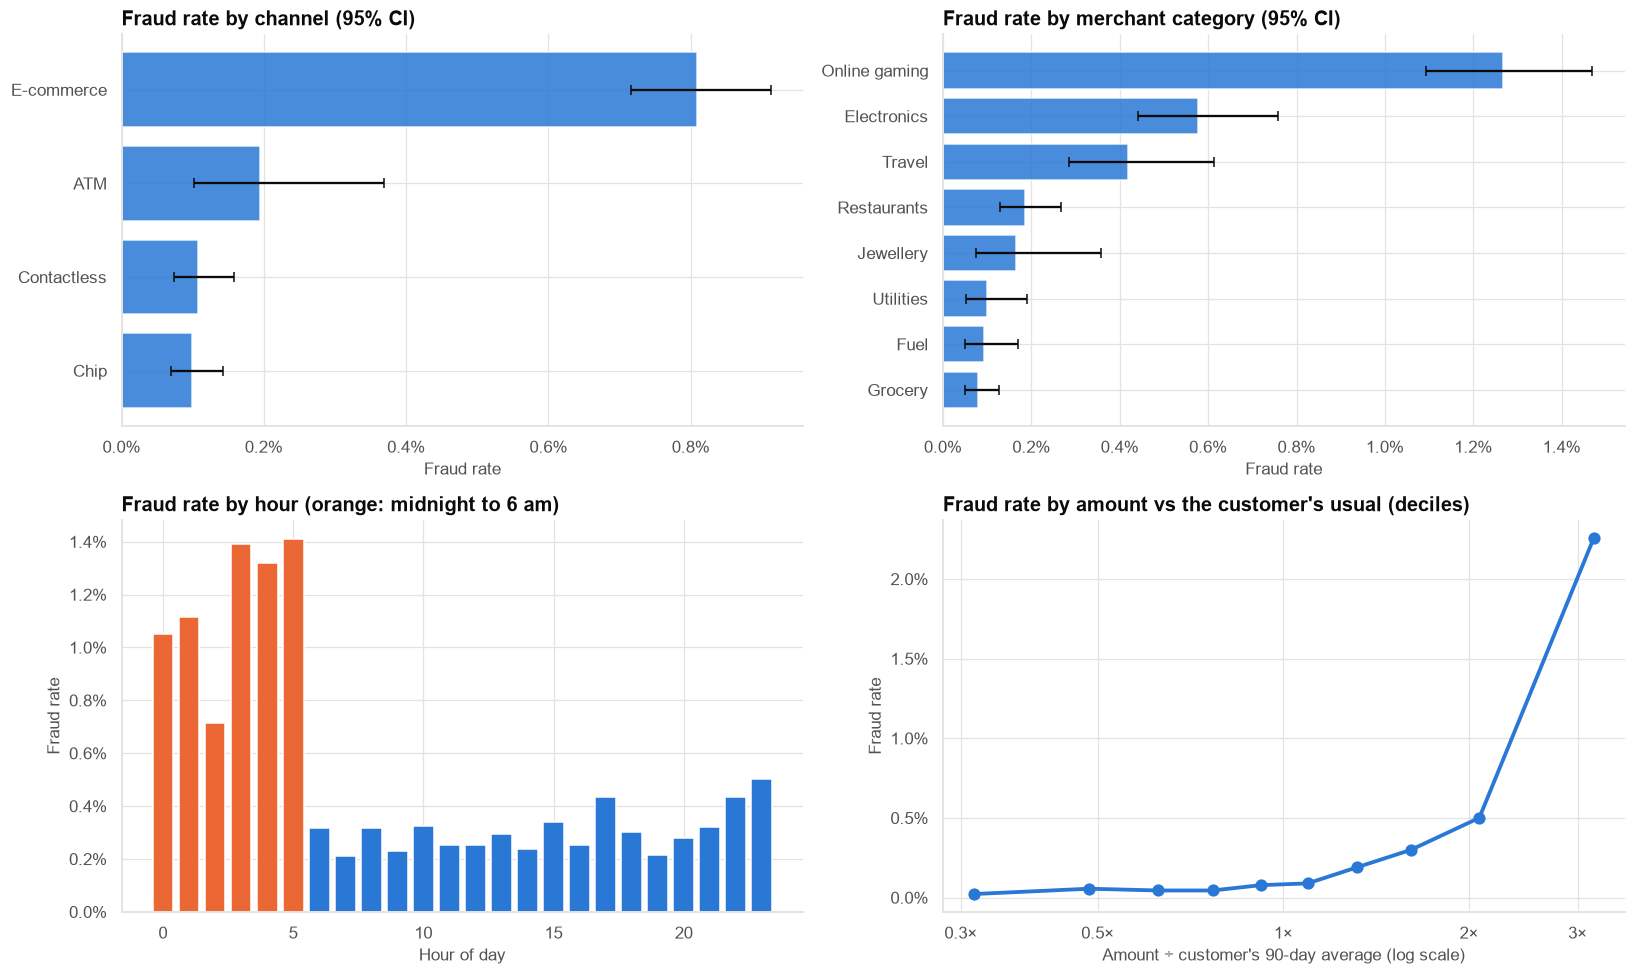

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col, lab in [(axes[0, 0], "channel", "Channel"), (axes[0, 1], "merchant_category", "Merchant category")]:
    g = train.groupby(col)["is_fraud"].agg(["sum", "size"])
    g["rate"] = g["sum"] / g["size"]
    g = g.sort_values("rate")
    ci = np.array([wilson(k, n) for k, n in zip(g["sum"], g["size"])])
    ax.barh(g.index, g["rate"], color=PRIMARY, alpha=0.85)
    ax.errorbar(g["rate"], np.arange(len(g)), xerr=[g["rate"] - ci[:, 0], ci[:, 1] - g["rate"]], fmt="none", color=INK, capsize=3)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
    ax.set(title=f"Fraud rate by {lab.lower()} (95% CI)", xlabel="Fraud rate")
ax = axes[1, 0]
g = train.groupby("hour")["is_fraud"].mean()
ax.bar(g.index, g.values, color=[HIGHLIGHT if h < 6 else PRIMARY for h in g.index])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set(title="Fraud rate by hour (orange: midnight to 6 am)", xlabel="Hour of day", ylabel="Fraud rate")
ax = axes[1, 1]
bins = pd.qcut(train["amount_vs_avg"], 10)
g = train.groupby(bins, observed=True).agg(x=("amount_vs_avg", "median"), rate=("is_fraud", "mean"))
ax.plot(g["x"], g["rate"], "o-", color=PRIMARY, lw=2.5, ms=7)
ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 1, 2, 3], ["0.3×", "0.5×", "1×", "2×", "3×"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set(title="Fraud rate by amount vs the customer's usual (deciles)", xlabel="Amount ÷ customer's 90-day average (log scale)",
       ylabel="Fraud rate")
fig.tight_layout()
save_fig(fig, "fig01_fraud_patterns", PATHS["figures"])
plt.show()

**Observation.** Fraud concentrates in **e-commerce** (about ten times the card-present rate), **online gaming** and
**electronics** merchants, **night-time** transactions, and transactions that are **large relative to the customer's
usual spend**. Even in the riskiest groups, fraud is only 1–2% of transactions: no single variable separates fraud
from genuine spending.

## Section 6 — The accuracy paradox

In [4]:
def metrics_at(y, flag, amount=None):
    tn, fp, fn, tp = confusion_matrix(y, flag, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn)
    spec = tn / (tn + fp)
    f1 = 2 * prec * rec / (prec + rec) if prec and rec else 0.0
    f2 = 5 * prec * rec / (4 * prec + rec) if prec and rec else 0.0
    out = {"alerts": tp + fp, "frauds caught (TP)": tp, "false alarms (FP)": fp, "frauds missed (FN)": fn,
           "accuracy": (tp + tn) / len(y), "balanced accuracy": (rec + spec) / 2, "precision": prec, "recall": rec,
           "specificity": spec, "F1": f1, "F2": f2, "MCC": matthews_corrcoef(y, flag) if tp + fp else 0.0}
    if amount is not None:
        missed_loss = LOSS_SHARE * amount[(y == 1) & (flag == 0)].sum()
        out["total cost (₹)"] = missed_loss + ALERT_COST * (tp + fp)
    return out

y_te, amt_te = test["is_fraud"].to_numpy(), test["amount"].to_numpy()
rule_te = ((test["amount"] > 50_000) | ((test["is_international"] == 1) & (test["channel"] == "E-commerce"))).astype(int).to_numpy()
base = pd.DataFrame({"Always 'genuine'": metrics_at(y_te, np.zeros_like(y_te), amt_te),
                     "Current rules": metrics_at(y_te, rule_te, amt_te),
                     "Random 1% of transactions": metrics_at(y_te, (rng.random(len(y_te)) < 0.01).astype(int), amt_te)}).T
save_table(base, "baseline_classifiers", PATHS["tables"])
base

,alerts,frauds caught (TP),false alarms (FP),frauds missed (FN),accuracy,balanced accuracy,precision,recall,specificity,F1,F2,MCC,total cost (₹)
Always 'genuine',0.0000,0.0000,0.0000,157.0000,0.9948,0.5000,NaN,0.0000,1.0000,0.0000,0.0000,0.0000,"1,447,432.0000"
Current rules,"1,256.0000",36.0000,"1,220.0000",121.0000,0.9553,0.5942,0.0287,0.2293,0.9591,0.0510,0.0955,0.0679,"733,416.0000"
Random 1% of transactions,296.0000,1.0000,295.0000,156.0000,0.9850,0.4982,0.0034,0.0064,0.9901,0.0044,0.0054,-0.0026,"1,489,136.0000"


**Observation.** A "model" that calls **every** transaction genuine is **99.5% accurate** in month 4, and catches no
fraud at all. The current rules are slightly *less* accurate (they raise false alarms) but catch about a fifth of fraud
cases, with a precision below 3%: about 34 false alarms per fraud found. Because one rule targets amounts above ₹50,000,
those few catches are large: the rules stop about **62% of fraud rupees**.

**Interpretation.** When 99.5% of cases are negative, accuracy is dominated by the negatives and says almost nothing
about fraud detection. The vendor's "99.6% accuracy" is barely better than doing nothing.

**The metrics that matter for rare positives**

| Metric | Formula | Business question |
|---|---|---|
| **Recall** (sensitivity, TPR) | TP / (TP + FN) | What share of fraud do we catch? |
| **Precision** (PPV) | TP / (TP + FP) | What share of alerts are real fraud? (analyst workload) |
| Specificity (TNR) | TN / (TN + FP) | What share of genuine transactions pass untouched? |
| False-positive rate | FP / (FP + TN) = 1 − specificity | What share of genuine customers are disturbed? |
| F1 / F2 | harmonic means of precision and recall (F2 weights recall more) | One-number summaries; ignore costs |
| MCC | correlation between prediction and truth | Balanced single number, robust to imbalance |
| **Cost** | ₹ lost to missed fraud + ₹ spent on alerts | What we actually want to minimise |

## Section 7 — The model

Logistic regression on the log of the amount, the amount relative to the customer's usual, and the other risk
signals, trained on months 1–3. For comparison, a gradient-boosting model (Case 13's playbook).

In [5]:
def preprocessor():
    return ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(drop="first"), CAT)])

X_tr, y_tr = train[NUM + CAT], train["is_fraud"].to_numpy()
X_te = test[NUM + CAT]
lr = make_pipeline(preprocessor(), LogisticRegression(max_iter=3000)).fit(X_tr, y_tr)
gbm = make_pipeline(preprocessor(), HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=12)).fit(X_tr, y_tr)
p_lr, p_gbm = lr.predict_proba(X_te)[:, 1], gbm.predict_proba(X_te)[:, 1]

def boot_metric(y, s, fn, n=1000):
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() > 0:
            vals.append(fn(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

perf = {}
for name, s in [("Logistic regression", p_lr), ("Gradient boosting", p_gbm)]:
    roc_ci, pr_ci = boot_metric(y_te, s, roc_auc_score), boot_metric(y_te, s, average_precision_score)
    perf[name] = {"ROC-AUC": roc_auc_score(y_te, s), "ROC-AUC CI": f"{roc_ci[0]:.3f}–{roc_ci[1]:.3f}",
                  "PR-AUC (average precision)": average_precision_score(y_te, s), "PR-AUC CI": f"{pr_ci[0]:.3f}–{pr_ci[1]:.3f}",
                  "PR-AUC of random scores (= prevalence)": y_te.mean()}
diff = []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    diff.append(average_precision_score(y_te[i], p_lr[i]) - average_precision_score(y_te[i], p_gbm[i]))
perf = pd.DataFrame(perf).T
save_table(perf, "model_performance_test", PATHS["tables"])
display(perf)
print(f"PR-AUC difference (logistic − GBM): {perf.iloc[0, 2] - perf.iloc[1, 2]:+.3f}, "
      f"bootstrap 95% CI {np.percentile(diff, 2.5):+.3f} to {np.percentile(diff, 97.5):+.3f}")

,ROC-AUC,ROC-AUC CI,PR-AUC (average precision),PR-AUC CI,PR-AUC of random scores (= prevalence)
Logistic regression,0.9661,0.955–0.976,0.4283,0.349–0.509,0.0052
Gradient boosting,0.9530,0.935–0.967,0.2510,0.188–0.327,0.0052


PR-AUC difference (logistic − GBM): +0.177, bootstrap 95% CI +0.125 to +0.223


**Observation.** On month 4, logistic regression has a **ROC-AUC of about 0.97** but a **PR-AUC of only about 0.4**.
Gradient boosting is **reliably worse**: PR-AUC about 0.25, and the bootstrap CI of the difference (logistic − GBM,
about +0.13 to +0.22) excludes zero.

**Interpretation.** Both numbers describe the same scores:
- **ROC-AUC 0.97**: pick one fraud and one genuine transaction at random, and the model ranks the fraud higher 97% of
  the time. Impressive, but with 199 genuine transactions per fraud, even a 1% false-positive rate means hundreds of
  false alarms.
- **PR-AUC ≈ 0.4**: the average precision across recall levels. Its "random" baseline is the prevalence (0.005), not
  0.5. It shows directly how clean the alert queue would be.

With only about 320 training frauds, the flexible gradient-boosting model has too little signal to learn more than the
logistic model already captures: Case 13's lesson ("ML is worth it only when there is non-linear signal **and** enough
data").

## Section 8 — ROC vs precision-recall curves

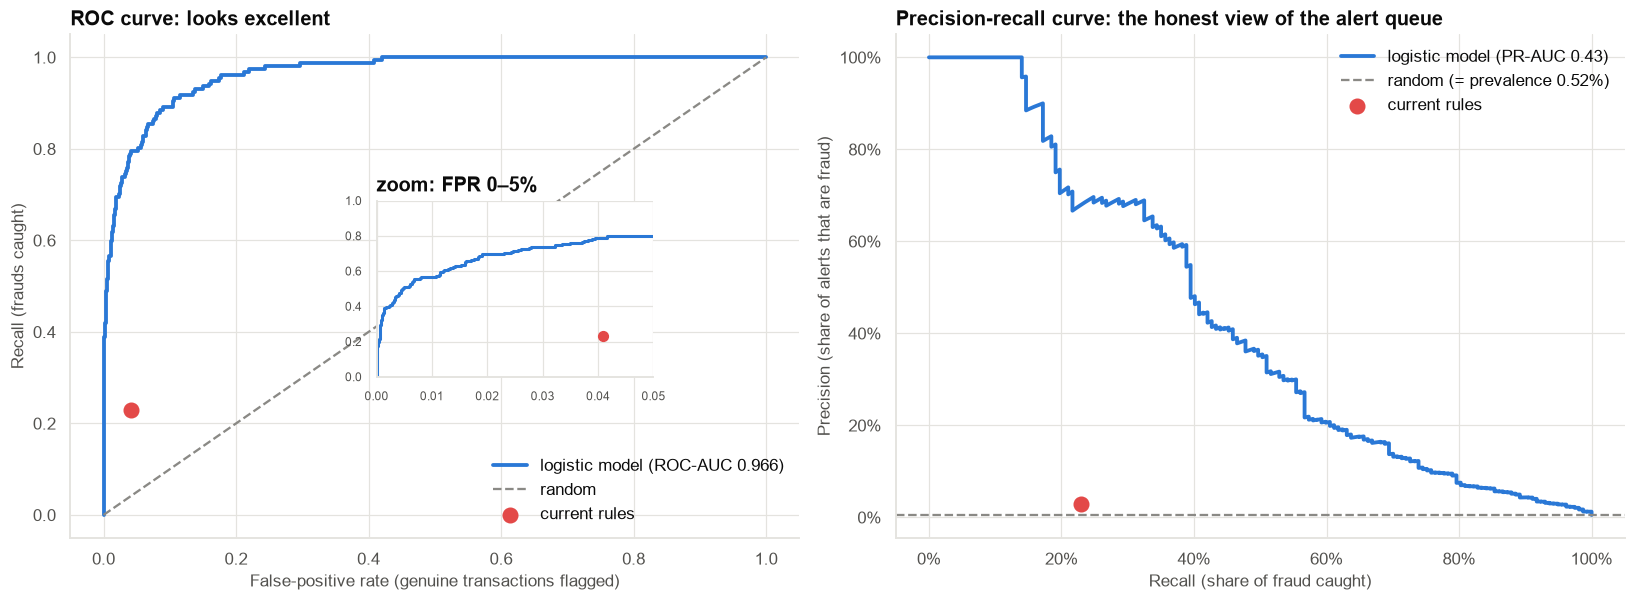

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
fpr, tpr, _ = roc_curve(y_te, p_lr)
prec, rec, _ = precision_recall_curve(y_te, p_lr)
rule_m = base.loc["Current rules"]
ax = axes[0]
ax.plot(fpr, tpr, color=PRIMARY, lw=2.5, label=f"logistic model (ROC-AUC {perf.iloc[0, 0]:.3f})")
ax.plot([0, 1], [0, 1], color=INK_MUTED, ls="--", label="random")
ax.scatter([1 - rule_m["specificity"]], [rule_m["recall"]], s=90, color=COLORS["red"], zorder=5, label="current rules")
ax.set(xlabel="False-positive rate (genuine transactions flagged)", ylabel="Recall (frauds caught)",
       title="ROC curve: looks excellent")
ax.legend(frameon=False, loc="lower right")
axin = ax.inset_axes([0.42, 0.32, 0.38, 0.35])
axin.plot(fpr, tpr, color=PRIMARY, lw=2)
axin.scatter([1 - rule_m["specificity"]], [rule_m["recall"]], s=40, color=COLORS["red"], zorder=5)
axin.set(xlim=(0, 0.05), ylim=(0, 1), title="zoom: FPR 0–5%")
axin.tick_params(labelsize=8); axin.title.set_fontsize(9)
ax = axes[1]
ax.plot(rec, prec, color=PRIMARY, lw=2.5, label=f"logistic model (PR-AUC {perf.iloc[0, 2]:.2f})")
ax.axhline(y_te.mean(), color=INK_MUTED, ls="--", label=f"random (= prevalence {y_te.mean():.2%})")
ax.scatter([rule_m["recall"]], [rule_m["precision"]], s=90, color=COLORS["red"], zorder=5, label="current rules")
ax.yaxis.set_major_formatter(pctfmt); ax.xaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Recall (share of fraud caught)", ylabel="Precision (share of alerts that are fraud)",
       title="Precision-recall curve: the honest view of the alert queue")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
save_fig(fig, "fig02_roc_vs_pr", PATHS["figures"])
plt.show()

**Observation.** On the ROC plot, the model's curve hugs the top-left corner, and the rules look reasonable too. On
the precision-recall plot, the picture is sobering: to catch half of the fraud, only about one alert in three is real;
to catch 80%, fewer than one in ten. The current rules sit far below the model's curve on both plots.

**Interpretation.** The ROC curve's x-axis (false-positive **rate**) divides by the huge number of genuine
transactions, so even many false alarms look small. Precision divides by the number of **alerts**, which is what the
analysts actually work through.

### 8.1 The same model at different fraud rates

In [7]:
pos, neg = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
prev_rows = []
for prev in [0.001, 0.005, 0.02, 0.10, 0.50]:
    n_neg = len(pos) * (1 - prev) / prev
    idx_neg = rng.choice(neg, int(n_neg), replace=n_neg > len(neg))   # resample genuine transactions to reach the target rate
    idx = np.r_[pos, idx_neg]
    prev_rows.append({"fraud rate": prev, "ROC-AUC": roc_auc_score(y_te[idx], p_lr[idx]),
                      "PR-AUC": average_precision_score(y_te[idx], p_lr[idx])})
prev_tbl = pd.DataFrame(prev_rows).set_index("fraud rate")
save_table(prev_tbl, "prevalence_sensitivity", PATHS["tables"])
prev_tbl

,ROC-AUC,PR-AUC
fraud rate,,
0.0010,0.9661,0.2465
0.0050,0.9673,0.4424
0.0200,0.9667,0.6055
0.1000,0.9673,0.8356
0.5000,0.9592,0.9587


**Observation.** Holding the model's scores fixed and changing only how many genuine transactions there are per fraud,
ROC-AUC stays at about 0.96–0.97, while PR-AUC ranges from about 0.25 (0.1% fraud) through 0.44 (0.5%) to about 0.96
(50% fraud).

**Interpretation.** ROC-AUC measures **ranking**, which does not depend on prevalence. PR-AUC measures how useful the
ranking is **at this prevalence**. Report both, but decide with precision-recall and costs. Never compare PR-AUCs
across datasets with different fraud rates.

## Section 9 — Should we rebalance the data?

The vendor recommends "fixing the imbalance" before training. Four common options, all trained on months 1–3:
- **class weights**: each fraud counts as many genuine transactions in the loss;
- **random undersampling**: keep all frauds and 10% of genuine transactions;
- **random oversampling**: copy frauds until they are 10% of the data;
- **SMOTE**: create synthetic frauds by interpolating between neighbouring frauds.

In [8]:
def fit_lr(X, y, w=None):
    return make_pipeline(preprocessor(), LogisticRegression(max_iter=3000)).fit(X, y, logisticregression__sample_weight=w)

pos_tr, neg_tr = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
variants = {"Standard (no rebalancing)": lr}
w = np.where(y_tr == 1, len(neg_tr) / len(pos_tr), 1.0)
variants["Class weights (balanced)"] = fit_lr(X_tr, y_tr, w)
keep = np.r_[pos_tr, rng.choice(neg_tr, int(0.10 * len(neg_tr)), replace=False)]
variants["Undersample genuine to 10%"] = fit_lr(X_tr.iloc[keep], y_tr[keep])
n_add = int(len(neg_tr) / 9) - len(pos_tr)
over = np.r_[np.arange(len(y_tr)), rng.choice(pos_tr, n_add, replace=True)]
variants["Oversample fraud to 10%"] = fit_lr(X_tr.iloc[over], y_tr[over])

# SMOTE by hand: synthetic frauds on the line between a fraud and one of its 5 nearest fraud neighbours
# (in the standardised / one-hot space). Note: interpolating one-hot columns creates fractional categories,
# a known weakness of plain SMOTE with categorical data.
pre_s = preprocessor().fit(X_tr)
Z = pre_s.transform(X_tr)
Z = Z.toarray() if hasattr(Z, "toarray") else Z
Zp = Z[pos_tr]
nn = NearestNeighbors(n_neighbors=6).fit(Zp)
nbr = nn.kneighbors(Zp, return_distance=False)[:, 1:]
base_i = rng.integers(0, len(Zp), n_add)
mate = nbr[base_i, rng.integers(0, 5, n_add)]
synth = Zp[base_i] + rng.random((n_add, 1)) * (Zp[mate] - Zp[base_i])
Zs, ys = np.vstack([Z, synth]), np.r_[y_tr, np.ones(n_add, dtype=int)]
smote_clf = LogisticRegression(max_iter=3000).fit(Zs, ys)
Zt = pre_s.transform(X_te); Zt = Zt.toarray() if hasattr(Zt, "toarray") else Zt

scores = {k: m.predict_proba(X_te)[:, 1] for k, m in variants.items()}
scores["SMOTE to 10%"] = smote_clf.predict_proba(Zt)[:, 1]
reb = pd.DataFrame({k: {"ROC-AUC": roc_auc_score(y_te, s), "PR-AUC": average_precision_score(y_te, s),
                        "mean predicted fraud rate": s.mean(), "actual fraud rate": y_te.mean(),
                        "Brier score": brier_score_loss(y_te, s), "alerts at p > 0.5": int((s > 0.5).sum()),
                        "frauds caught at p > 0.5": int(((s > 0.5) & (y_te == 1)).sum())} for k, s in scores.items()}).T
save_table(reb, "rebalancing_comparison", PATHS["tables"])
reb

,ROC-AUC,PR-AUC,mean predicted fraud rate,actual fraud rate,Brier score,alerts at p > 0.5,frauds caught at p > 0.5
Standard (no rebalancing),0.9661,0.4283,0.0038,0.0052,0.0039,29.0000,26.0000
Class weights (balanced),0.9649,0.3981,0.1688,0.0052,0.0789,"3,367.0000",142.0000
Undersample genuine to 10%,0.9650,0.4160,0.0211,0.0052,0.0062,193.0000,73.0000
Oversample fraud to 10%,0.9660,0.4141,0.0456,0.0052,0.0142,539.0000,98.0000
SMOTE to 10%,0.9672,0.4092,0.0407,0.0052,0.0142,571.0000,100.0000


**Observation.**
- **Ranking is essentially unchanged.** ROC-AUC and PR-AUC are almost the same for all five versions.
- **Probabilities are not.** Every rebalanced model predicts fraud rates many times the real 0.5%: from about 2% (undersampling) to
  about 17% (class weights). Brier scores get much worse.
- At the default **p > 0.5** threshold, the standard model raises 29 alerts and the rebalanced ones 193 to 3,367.
  That is the only real "benefit" of rebalancing: it **moves the threshold**.

**Interpretation.** Rebalancing does not create information. A logistic model already ranks transactions the same way
whatever the class balance; reweighting mostly shifts the **intercept**, inflating every probability. You can get the
same alerts by **lowering the threshold** on the standard model, without destroying its calibration.

### 9.1 Undoing the damage: prior correction

,weighting ratio,mean p before,mean p after correction,Brier before,Brier after
Class weights (balanced),278.5031,0.1688,0.0033,0.0789,0.0041
Undersample genuine to 10%,10.0000,0.0211,0.0036,0.0062,0.0039
Oversample fraud to 10%,30.9441,0.0456,0.0035,0.0142,0.0040
SMOTE to 10%,30.9441,0.0407,0.0038,0.0142,0.0039
Standard (no rebalancing),1.0000,0.0038,0.0038,0.0039,0.0039


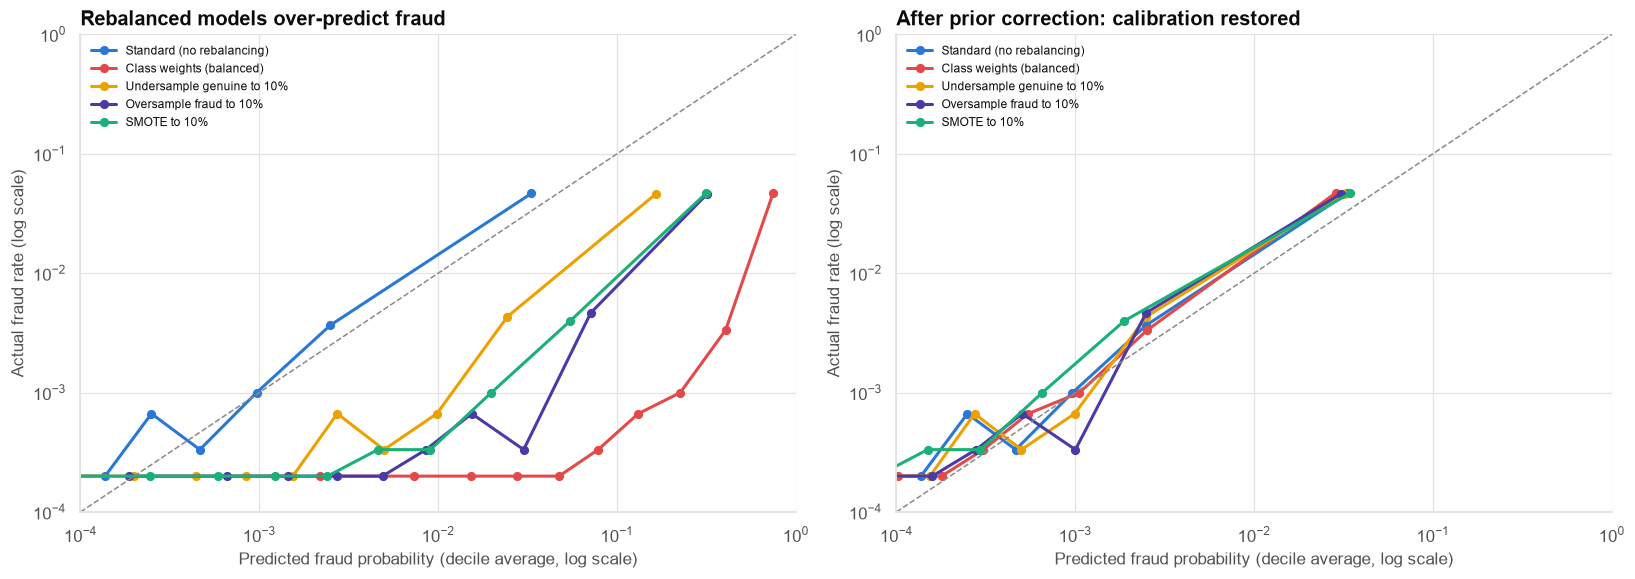

In [9]:
def prior_correct(p, ratio):
    # ratio = how many times the positives were up-weighted (or negatives down-weighted) relative to reality.
    odds = p / (1 - p) / ratio
    return odds / (1 + odds)

ratios = {"Class weights (balanced)": len(neg_tr) / len(pos_tr), "Undersample genuine to 10%": 1 / 0.10,
          "Oversample fraud to 10%": (len(pos_tr) + n_add) / len(pos_tr), "SMOTE to 10%": (len(pos_tr) + n_add) / len(pos_tr)}
corr = {k: prior_correct(scores[k], r) for k, r in ratios.items()}
corr_tbl = pd.DataFrame({k: {"weighting ratio": ratios[k], "mean p before": scores[k].mean(), "mean p after correction": v.mean(),
                             "Brier before": brier_score_loss(y_te, scores[k]), "Brier after": brier_score_loss(y_te, v)}
                         for k, v in corr.items()}).T
corr_tbl.loc["Standard (no rebalancing)"] = [1.0, scores["Standard (no rebalancing)"].mean(), scores["Standard (no rebalancing)"].mean(),
                                             brier_score_loss(y_te, scores["Standard (no rebalancing)"]),
                                             brier_score_loss(y_te, scores["Standard (no rebalancing)"])]
save_table(corr_tbl, "prior_correction", PATHS["tables"])
display(corr_tbl)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
def cal_curve(ax, s, lab, col, ls="-"):
    q = pd.qcut(s, 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": s, "y": y_te, "q": q}).groupby("q").mean()
    ax.plot(g["p"], g["y"].clip(lower=2e-4), marker="o", ls=ls, color=col, lw=2, ms=5, label=lab)
cols = [PRIMARY, COLORS["red"], COLORS["yellow"], COLORS["violet"], COLORS["aqua"]]
for ax, use_corr in zip(axes, [False, True]):
    for (k, s), col in zip(scores.items(), cols):
        cal_curve(ax, corr.get(k, s) if use_corr else s, k, col)
    ax.plot([1e-4, 1], [1e-4, 1], color=INK_MUTED, ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlim=(1e-4, 1), ylim=(1e-4, 1), xlabel="Predicted fraud probability (decile average, log scale)",
           ylabel="Actual fraud rate (log scale)",
           title="After prior correction: calibration restored" if use_corr else "Rebalanced models over-predict fraud")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
save_fig(fig, "fig03_rebalancing_calibration", PATHS["figures"])
plt.show()

**Observation.** Dividing each rebalanced model's odds by its weighting ratio (**prior correction**) brings the average
prediction back close to the training-period fraud rate and repairs the Brier score. The corrected curves sit on top
of the standard model's curve. All of them lie slightly **above** the diagonal in the riskiest deciles: month 4 has
more fraud than the training months (drift, Section 14), which no rebalancing can fix.

**Rule.**

| Situation | Do this |
|---|---|
| Logistic / GLM, you need probabilities (cost decisions) | **Don't rebalance.** Use the standard fit and choose the threshold from costs |
| Training is slow or data is huge | **Undersample** genuine transactions to save compute, then **prior-correct** |
| Tree models with very few positives | Class weights can help the trees *find* the minority; then recalibrate (prior correction, Platt or isotonic on a validation set) |
| SMOTE | Rarely needed for logistic models; creates unrealistic points with categorical data; never apply it **before** splitting train/test (leakage) |

## Section 10 — Choosing the threshold

Thresholds chosen on months 1–3 (out-of-fold): F1-optimal 0.264, cost-optimal 0.0072, capacity (top 1%) 0.0590


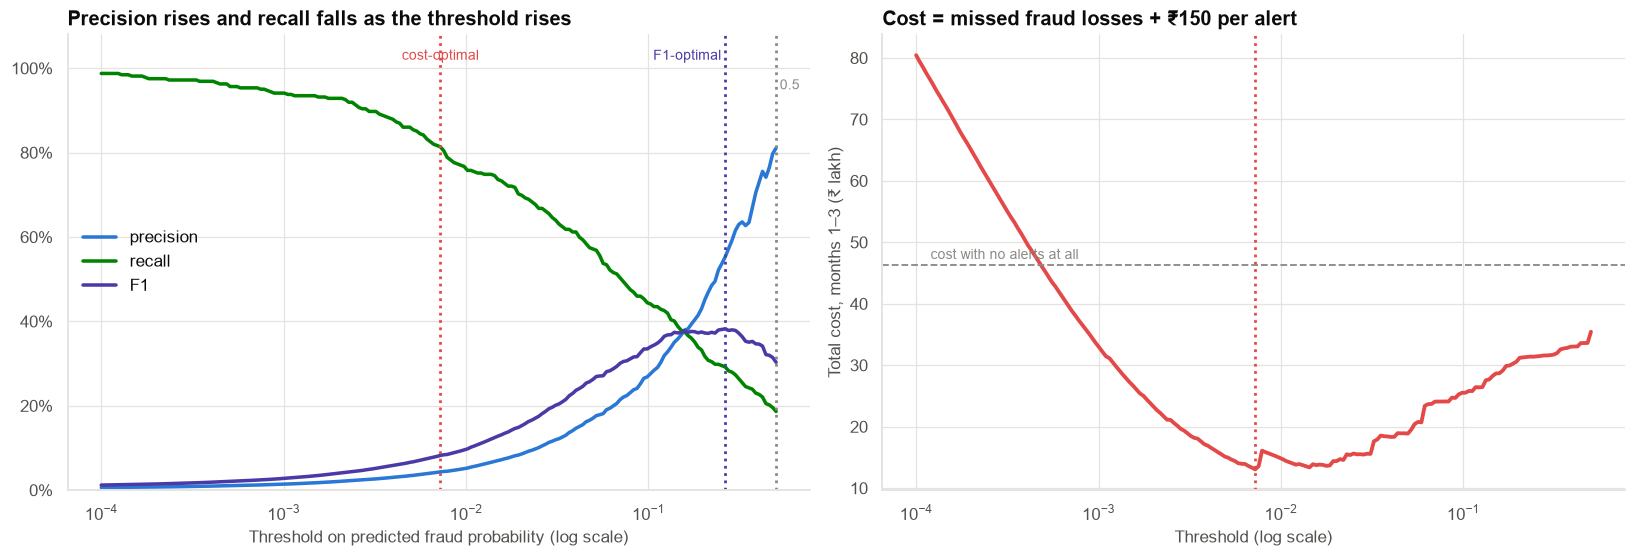

In [10]:
# Out-of-fold scores on months 1–3: we choose thresholds on these, then evaluate the choice on month 4.
oof = np.zeros(len(train))
for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=12).split(X_tr, y_tr):
    m = make_pipeline(preprocessor(), LogisticRegression(max_iter=3000)).fit(X_tr.iloc[tr_i], y_tr[tr_i])
    oof[va_i] = m.predict_proba(X_tr.iloc[va_i])[:, 1]
amt_tr = train["amount"].to_numpy()

grid = np.unique(np.r_[np.logspace(-4, -0.3, 200)])
curve = pd.DataFrame([{**metrics_at(y_tr, (oof >= t).astype(int), amt_tr), "threshold": t} for t in grid]).set_index("threshold")
t_f1 = curve["F1"].idxmax()
t_cost = curve["total cost (₹)"].idxmin()
t_cap = np.quantile(oof, 1 - CAPACITY_SHARE)
print(f"Thresholds chosen on months 1–3 (out-of-fold): F1-optimal {t_f1:.3f}, cost-optimal {t_cost:.4f}, "
      f"capacity (top 1%) {t_cap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ax = axes[0]
for col, c, lab in [("precision", PRIMARY, "precision"), ("recall", COLORS["green"], "recall"), ("F1", COLORS["violet"], "F1")]:
    ax.plot(curve.index, curve[col], color=c, lw=2.3, label=lab)
for t, lab, c, yy, ha in [(t_f1, "F1-optimal", COLORS["violet"], 1.02, "right"), (t_cost, "cost-optimal", COLORS["red"], 1.02, "center"),
                          (0.5, "0.5", INK_MUTED, 0.95, "left")]:
    ax.axvline(t, color=c, ls=":", lw=1.8)
    ax.text(t * (0.95 if ha == "right" else 1.05 if ha == "left" else 1), yy, lab, ha=ha, fontsize=9, color=c)
ax.set_xscale("log"); ax.yaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Threshold on predicted fraud probability (log scale)", ylim=(0, 1.08),
       title="Precision rises and recall falls as the threshold rises")
ax.legend(frameon=False, loc="center left")
ax = axes[1]
ax.plot(curve.index, curve["total cost (₹)"] / 1e5, color=COLORS["red"], lw=2.5)
ax.axvline(t_cost, color=COLORS["red"], ls=":", lw=1.8)
ax.axhline(LOSS_SHARE * amt_tr[y_tr == 1].sum() / 1e5, color=INK_MUTED, ls="--", lw=1.2)
ax.text(curve.index.min() * 1.2, LOSS_SHARE * amt_tr[y_tr == 1].sum() / 1e5 * 1.02, "cost with no alerts at all", fontsize=9, color=INK_MUTED)
ax.set_xscale("log")
ax.set(xlabel="Threshold (log scale)", ylabel="Total cost, months 1–3 (₹ lakh)",
       title="Cost = missed fraud losses + ₹150 per alert")
fig.tight_layout()
save_fig(fig, "fig04_threshold_curves", PATHS["figures"])
plt.show()

**Observation.** The cost-optimal threshold is far **below** 0.5, and below the F1-optimal one: missing a fraud costs
on average far more than reviewing a genuine transaction, so it pays to accept more false alarms.

**The amount-aware rule.** A fraud on a ₹50,000 purchase costs a hundred times more than one on ₹500. If the
probabilities are **calibrated**, the expected loss of letting a transaction through is p × 80% × amount, and an alert
is worth raising when that exceeds ₹150:

  **alert if  p × 0.8 × amount > ₹150**

This needs no tuning at all, but it is only as good as the model's **calibration** (Section 9).

## Section 11 — Comparing policies on month 4 (unseen data)

In [11]:
cap_n = int(CAPACITY_SHARE * len(test))
top_k = np.zeros(len(test), dtype=int); top_k[np.argsort(-p_lr)[:cap_n]] = 1
ev_flag = (p_lr * LOSS_SHARE * amt_te > ALERT_COST).astype(int)
ev_bal = (scores["Class weights (balanced)"] * LOSS_SHARE * amt_te > ALERT_COST).astype(int)
policies = {
    "No alerts": np.zeros(len(test), dtype=int),
    "Current rules": rule_te,
    "Model, p > 0.5": (p_lr > 0.5).astype(int),
    "Model, F1-optimal threshold": (p_lr >= t_f1).astype(int),
    "Model, cost-optimal threshold": (p_lr >= t_cost).astype(int),
    f"Model, top 1% ({cap_n} alerts, capacity)": top_k,
    "Model, amount-aware (p × 0.8 × amount > ₹150)": ev_flag,
    "Amount-aware rule on the class-weighted model": ev_bal,
}
pol = pd.DataFrame({k: metrics_at(y_te, f, amt_te) for k, f in policies.items()}).T
pol["fraud ₹ caught (%)"] = [100 * amt_te[(y_te == 1) & (f == 1)].sum() / amt_te[y_te == 1].sum() for f in policies.values()]
pol["saving vs no alerts (₹)"] = pol.loc["No alerts", "total cost (₹)"] - pol["total cost (₹)"]
show = ["alerts", "frauds caught (TP)", "precision", "recall", "fraud ₹ caught (%)", "total cost (₹)", "saving vs no alerts (₹)"]
save_table(pol, "policy_comparison_month4", PATHS["tables"])
pol[show]

,alerts,frauds caught (TP),precision,recall,fraud ₹ caught (%),total cost (₹),saving vs no alerts (₹)
No alerts,0.0000,0.0000,NaN,0.0000,0.0000,"1,447,432.0000",0.0000
Current rules,"1,256.0000",36.0000,0.0287,0.2293,62.3460,"733,416.0000","714,016.0000"
"Model, p > 0.5",29.0000,26.0000,0.8966,0.1656,9.5026,"1,314,238.0000","133,194.0000"
"Model, F1-optimal threshold",61.0000,42.0000,0.6885,0.2675,29.8089,"1,025,118.0000","422,314.0000"
"Model, cost-optimal threshold","2,066.0000",132.0000,0.0639,0.8408,86.5516,"504,556.0000","942,876.0000"
"Model, top 1% (300 alerts, capacity)",300.0000,87.0000,0.2900,0.5541,69.2520,"490,056.0000","957,376.0000"
"Model, amount-aware (p × 0.8 × amount > ₹150)",890.0000,82.0000,0.0921,0.5223,83.7135,"369,236.0000","1,078,196.0000"
Amount-aware rule on the class-weighted model,"13,353.0000",155.0000,0.0116,0.9873,99.9375,"2,003,854.0000","-556,422.0000"


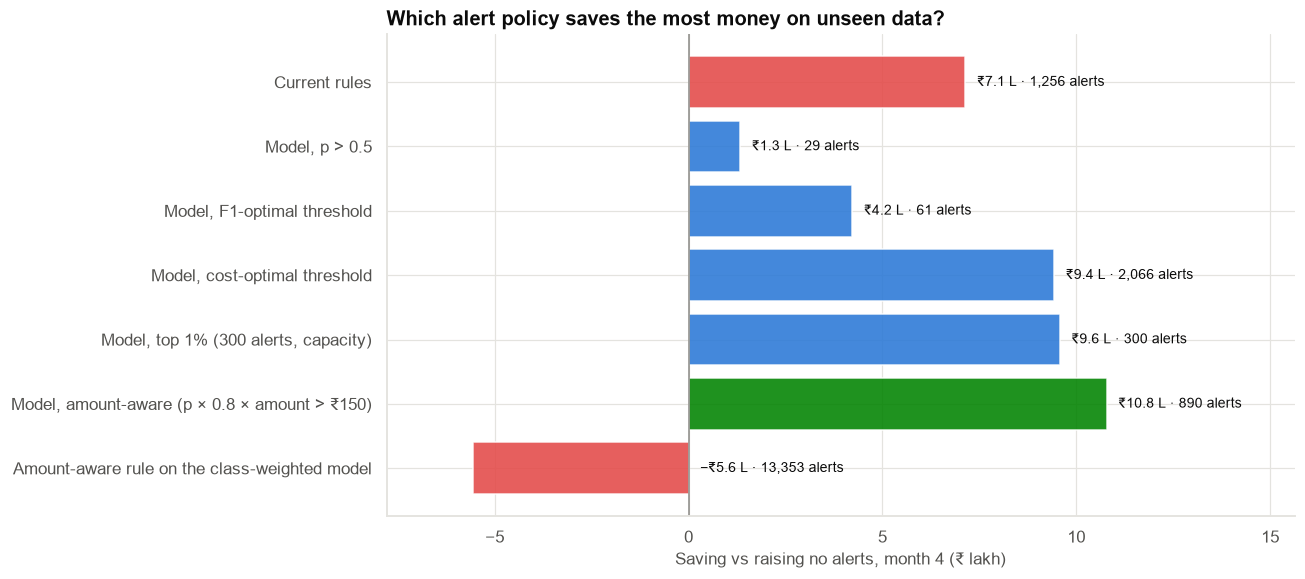

In [12]:
fig, ax = plt.subplots(figsize=(12, 5.4))
order = [k for k in pol.index if k != "No alerts"][::-1]
vals = pol.loc[order, "saving vs no alerts (₹)"] / 1e5
cols = [COLORS["green"] if "amount-aware (p" in k else (COLORS["red"] if "rules" in k or "class-weighted" in k else PRIMARY) for k in order]
ax.barh(order, vals, color=cols, alpha=0.88)
for i, (v, k) in enumerate(zip(vals, order)):
    ax.text(max(v, 0) + 0.3, i, f"₹{v:,.1f} L · {int(pol.loc[k, 'alerts']):,} alerts".replace("₹-", "−₹"), va="center",
            ha="left", fontsize=9)
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="Saving vs raising no alerts, month 4 (₹ lakh)", title="Which alert policy saves the most money on unseen data?")
ax.set_xlim(min(vals.min() * 1.4, -1), vals.max() * 1.45)
fig.tight_layout()
save_fig(fig, "fig05_policy_savings", PATHS["figures"])
plt.show()

**Observation (month 4).**
- **p > 0.5** raises only 29 alerts (90% precision, but 17% recall) and saves just ₹1.3 lakh.
- The **F1-optimal** threshold improves the balance of precision and recall but ignores ₹ (₹4.2 lakh).
- The **current rules** save about ₹7.1 lakh, mostly through the ₹50,000 rule.
- The **cost-optimal** flat threshold (₹9.4 lakh, but 2,066 alerts) and the **top-1% capacity** policy (₹9.6 lakh,
  300 alerts) both beat the rules.
- The **amount-aware** rule saves the most, about **₹10.8 lakh**, catching 84% of fraud rupees, but it raises 890
  alerts, three times the analysts' capacity.
- Applying the same amount-aware rule to the **class-weighted** model is a disaster: its inflated probabilities flag
  over 13,000 transactions, and alert costs swamp the savings (a net **loss** of ₹5.6 lakh). **Calibration is not
  optional when probabilities are turned into money.**

**Interpretation.** The best threshold depends on what is being optimised: number of frauds (recall), clean queues
(precision), or **money**. The business cares about money and capacity, so the threshold should come from costs,
check against capacity, and favour large transactions.

## Section 12 — Capacity check

In [13]:
best = pol["total cost (₹)"].drop("No alerts").idxmin()
print(f"Lowest-cost policy on month 4: {best}")
print(f"Its alerts: {int(pol.loc[best, 'alerts']):,} = {pol.loc[best, 'alerts'] / len(test):.2%} of transactions "
      f"(capacity {CAPACITY_SHARE:.0%} = {cap_n})")
# Capacity-constrained amount-aware policy: rank by expected loss, review the top 1%.
el = p_lr * LOSS_SHARE * amt_te
cap_el = np.zeros(len(test), dtype=int); cap_el[np.argsort(-el)[:cap_n]] = 1
cap_el = cap_el * (el > ALERT_COST)
cap_row = pd.DataFrame({"Model, amount-aware within capacity": metrics_at(y_te, cap_el, amt_te)}).T
cap_row["fraud ₹ caught (%)"] = 100 * amt_te[(y_te == 1) & (cap_el == 1)].sum() / amt_te[y_te == 1].sum()
cap_row["saving vs no alerts (₹)"] = pol.loc["No alerts", "total cost (₹)"] - cap_row["total cost (₹)"]
pol = pd.concat([pol, cap_row])
save_table(pol, "policy_comparison_month4", PATHS["tables"])
pol.loc[["Current rules", f"Model, top 1% ({cap_n} alerts, capacity)", "Model, amount-aware (p × 0.8 × amount > ₹150)",
         "Model, amount-aware within capacity"], show]

Lowest-cost policy on month 4: Model, amount-aware (p × 0.8 × amount > ₹150)
Its alerts: 890 = 2.97% of transactions (capacity 1% = 300)


,alerts,frauds caught (TP),precision,recall,fraud ₹ caught (%),total cost (₹),saving vs no alerts (₹)
Current rules,"1,256.0000",36.0000,0.0287,0.2293,62.3460,"733,416.0000","714,016.0000"
"Model, top 1% (300 alerts, capacity)",300.0000,87.0000,0.2900,0.5541,69.2520,"490,056.0000","957,376.0000"
"Model, amount-aware (p × 0.8 × amount > ₹150)",890.0000,82.0000,0.0921,0.5223,83.7135,"369,236.0000","1,078,196.0000"
"Model, amount-aware within capacity",300.0000,52.0000,0.1733,0.3312,71.6347,"455,568.0000","991,864.0000"


**Observation.** The unconstrained amount-aware rule needs three times the analysts' capacity. Ranking by **expected
loss** (p × 0.8 × amount) and reviewing only the top 1% keeps about 92% of its saving (₹9.9 lakh) and catches about
72% of fraud rupees, with 300 alerts. It catches fewer fraud **cases** (33%) than ranking by probability alone (55%),
because it spends analyst time on large transactions; in rupees it does slightly better (₹9.9 vs ₹9.6 lakh), a
difference well within the noise.

**Recommended policy:** rank by expected loss and review the top 1%. It is aligned with what the bank actually loses,
respects capacity, and becomes more valuable as amounts become more varied. If the bank values fraud **counts**
(customer harm, regulatory reporting) as much as rupees, ranking by probability is a defensible alternative.

## Section 13 — How certain are these numbers?

In [14]:
rec_pol = "Model, amount-aware within capacity"
flag = cap_el
tp = int(((flag == 1) & (y_te == 1)).sum()); n_alert = int(flag.sum()); n_fraud = int(y_te.sum())
prec_ci, rec_ci = wilson(tp, n_alert), wilson(tp, n_fraud)
bs = []
for _ in range(2000):
    i = rng.integers(0, len(y_te), len(y_te))
    f, y_, a_ = flag[i], y_te[i], amt_te[i]
    cost_none = LOSS_SHARE * a_[y_ == 1].sum()
    cost_pol = LOSS_SHARE * a_[(y_ == 1) & (f == 0)].sum() + ALERT_COST * f.sum()
    tp_i = ((f == 1) & (y_ == 1)).sum()
    bs.append([tp_i / max(f.sum(), 1), tp_i / max(y_.sum(), 1), cost_none - cost_pol,
               (cost_none - cost_pol) - (cost_none - (LOSS_SHARE * a_[(y_ == 1) & (rule_te[i] == 0)].sum() + ALERT_COST * rule_te[i].sum()))])
bs = np.array(bs)
unc = pd.DataFrame({"estimate": [tp / n_alert, tp / n_fraud, pol.loc[rec_pol, "saving vs no alerts (₹)"],
                                 pol.loc[rec_pol, "saving vs no alerts (₹)"] - pol.loc["Current rules", "saving vs no alerts (₹)"]],
                    "95% CI low": [prec_ci[0], rec_ci[0], *np.percentile(bs[:, 2:], 2.5, axis=0)],
                    "95% CI high": [prec_ci[1], rec_ci[1], *np.percentile(bs[:, 2:], 97.5, axis=0)]},
                   index=["precision (Wilson CI)", "recall (Wilson CI)", "saving vs no alerts (₹, bootstrap)",
                          "extra saving vs current rules (₹, bootstrap)"])
save_table(unc, "uncertainty_recommended_policy", PATHS["tables"])
print(f"Recommended policy on month 4: {tp} of {n_fraud} frauds caught with {n_alert} alerts")
unc

Recommended policy on month 4: 52 of 157 frauds caught with 300 alerts


,estimate,95% CI low,95% CI high
precision (Wilson CI),0.1733,0.1347,0.2202
recall (Wilson CI),0.3312,0.2624,0.4081
"saving vs no alerts (₹, bootstrap)","991,864.0000","499,046.5500","1,606,718.4500"
"extra saving vs current rules (₹, bootstrap)","277,848.0000","78,389.4500","471,241.8000"


**Observation.** Recall is estimated from only 157 frauds, so its 95% CI runs from about 26% to 41%; precision, from
300 alerts, from about 13% to 22%. The rupee saving has a very wide interval (about ₹5–16 lakh), because a few large
frauds dominate the totals. The extra saving over the current rules (about ₹2.8 lakh, CI roughly ₹0.8–4.7 lakh) is
positive in every plausible scenario, but its size is uncertain.

**Interpretation.** With rare positives, **the number of positives, not the number of transactions, determines
precision**. 30,000 transactions sound like plenty; 160 frauds are not. Always report CIs for recall and precision, and
be wary of small "improvements" between models (Case 13's paired tests).

## Section 14 — Will it keep working? Monthly calibration and drift

,predicted fraud rate,actual fraud rate,actual ÷ predicted
month,,,
1,0.0035,0.0035,0.9838
2,0.0037,0.0040,1.0883
3,0.0036,0.0033,0.8994
4,0.0038,0.0052,1.3874


,predicted,actual,actual ÷ predicted,excess frauds (actual − predicted)
merchant_category,,,,
Jewellery,2.9787,6,2.0143,3.0213
Fuel,2.8923,5,1.7287,2.1077
Online gaming,68.1956,115,1.6863,46.8044
Grocery,3.5210,4,1.1361,0.4790
Restaurants,7.0599,7,0.9915,-0.0599
Electronics,16.5109,14,0.8479,-2.5109
Travel,9.0501,5,0.5525,-4.0501
Utilities,2.9512,1,0.3388,-1.9512


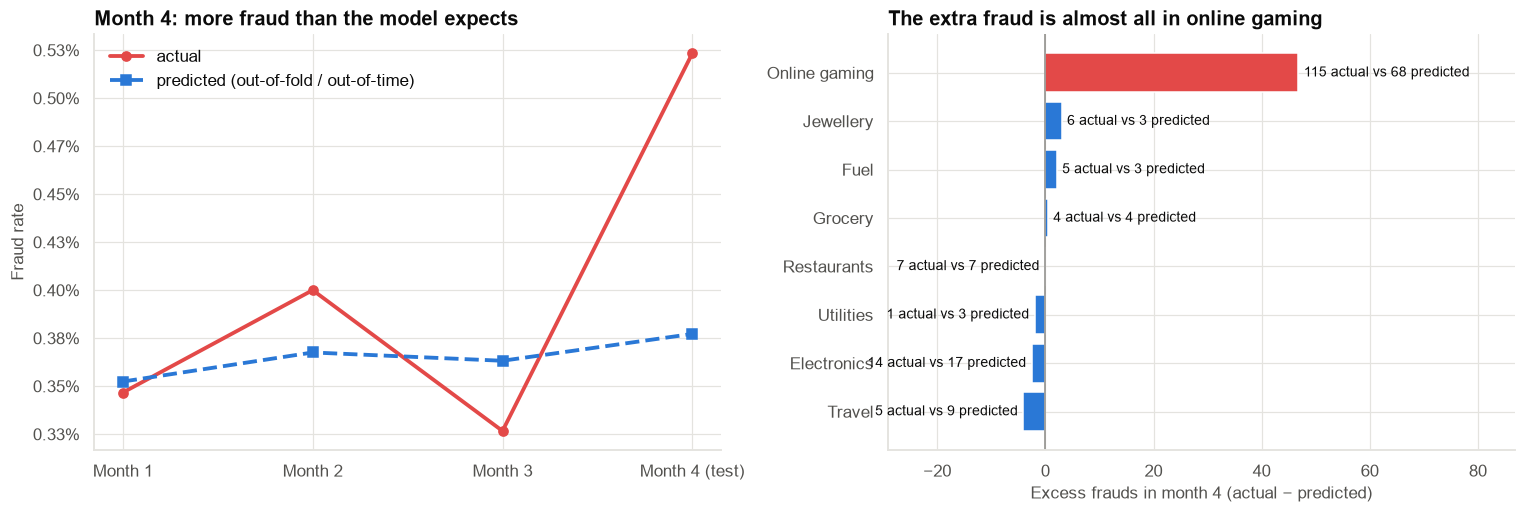

In [15]:
oof_all = pd.Series(np.nan, index=tx.index)
oof_all.loc[train.index] = oof
oof_all.loc[test.index] = p_lr
drift = pd.DataFrame({"predicted fraud rate": oof_all.groupby(tx["month"]).mean(), "actual fraud rate": tx.groupby("month")["is_fraud"].mean()})
drift["actual ÷ predicted"] = drift["actual fraud rate"] / drift["predicted fraud rate"]
by_merch = pd.DataFrame({"predicted": pd.Series(p_lr, index=test.index).groupby(test["merchant_category"]).sum(),
                         "actual": test.groupby("merchant_category")["is_fraud"].sum()})
by_merch["actual ÷ predicted"] = by_merch["actual"] / by_merch["predicted"]
by_merch["excess frauds (actual − predicted)"] = by_merch["actual"] - by_merch["predicted"]
save_table(drift, "monthly_calibration", PATHS["tables"])
save_table(by_merch, "month4_calibration_by_merchant", PATHS["tables"])
display(drift)
display(by_merch.sort_values("actual ÷ predicted", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.plot(drift.index, drift["actual fraud rate"], "o-", color=COLORS["red"], lw=2.5, label="actual")
ax.plot(drift.index, drift["predicted fraud rate"], "s--", color=PRIMARY, lw=2.5, label="predicted (out-of-fold / out-of-time)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2%}"))
ax.set_xticks([1, 2, 3, 4], ["Month 1", "Month 2", "Month 3", "Month 4 (test)"])
ax.set(ylabel="Fraud rate", title="Month 4: more fraud than the model expects")
ax.legend(frameon=False)
ax = axes[1]
bm = by_merch.sort_values("excess frauds (actual − predicted)")
ex_col = "excess frauds (actual − predicted)"
ax.barh(bm.index, bm[ex_col], color=[COLORS["red"] if v > 10 else PRIMARY for v in bm[ex_col]])
for i, (k, r_) in enumerate(bm.iterrows()):
    ax.text(r_[ex_col] + (1 if r_[ex_col] >= 0 else -1), i, f"{int(r_['actual'])} actual vs {r_['predicted']:.0f} predicted",
            va="center", ha="left" if r_[ex_col] >= 0 else "right", fontsize=9)
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set_xlim(bm[ex_col].min() - 25, bm[ex_col].max() + 40)
ax.set(xlabel="Excess frauds in month 4 (actual − predicted)", title="The extra fraud is almost all in online gaming")
fig.tight_layout()
save_fig(fig, "fig06_drift", PATHS["figures"])
plt.show()

**Observation.** In months 1–3, predicted and actual fraud rates agree. In month 4, actual fraud is about 39% higher than
predicted, and the excess is almost entirely in **online gaming** (115 actual vs about 68 predicted): a new fraud
pattern the model has not seen. Other categories with high ratios (jewellery, fuel) have only a handful of frauds.

**Interpretation.** This is **drift**: the relationship between features and fraud has changed. Ranking may still be
good (ROC-AUC remained high), but probabilities are too low for the affected segment, so the amount-aware rule
under-flags it. Fraud models need **monthly calibration monitoring by segment** and frequent retraining.

## Section 15 — Decision framework for imbalanced classification

| Question | Answer |
|---|---|
| Positives are rare: which headline metric? | **PR-AUC** (with prevalence as its baseline) plus recall/precision at the operating threshold; ROC-AUC only for ranking |
| Accuracy above 99%? | Compare with "always negative". Usually meaningless |
| Rebalance? | Not for logistic models when you need probabilities. If you do, **prior-correct** or recalibrate |
| SMOTE? | Rarely helps a logistic model; never before the train/test split |
| Threshold? | From **costs** (C_FP vs C_FN), the **amount at risk**, and **capacity**; never 0.5 by default |
| Costs differ by transaction? | Rank by **expected loss** p × loss, not by p |
| How many positives in the test set? | If < ~200, expect wide CIs on recall/precision; report them |
| Random or time-based split? | **Time-based** for fraud (patterns change) |
| ML (boosting) vs logistic? | Only if PR-AUC gain is reliable on out-of-time data and worth the cost (Case 13) |
| After deployment? | Monitor calibration by segment monthly; retrain when actual ÷ predicted drifts |

## Section 16 — Results

In [16]:
r = pol.loc[rec_pol]; ru = pol.loc["Current rules"]
acc_none = base.loc["Always 'genuine'", "accuracy"]
summary = pd.DataFrame({"Value": [
    f"{len(test):,} transactions, {int(y_te.sum())} frauds ({y_te.mean():.2%})",
    f"{acc_none:.2%} accuracy, catches nothing",
    f"precision {ru['precision']:.1%}, recall {ru['recall']:.0%}, {int(ru['alerts']):,} alerts",
    f"ROC-AUC {perf.iloc[0, 0]:.3f}, PR-AUC {perf.iloc[0, 2]:.2f} (random = {y_te.mean():.3f}); GBM PR-AUC {perf.iloc[1, 2]:.2f}",
    f"ranking unchanged; mean predicted fraud {reb.loc['Class weights (balanced)', 'mean predicted fraud rate']:.1%} (class weights) vs actual {y_te.mean():.2%}",
    f"{int(r['alerts'])} alerts: precision {r['precision']:.0%}, recall {r['recall']:.0%}, {r['fraud ₹ caught (%)']:.0f}% of fraud ₹ caught",
    f"₹{r['saving vs no alerts (₹)'] / 1e5:,.1f} lakh vs no alerts; ₹{(r['saving vs no alerts (₹)'] - ru['saving vs no alerts (₹)']) / 1e5:,.1f} lakh more than the rules",
    f"actual ÷ predicted fraud = {drift.loc[4, 'actual ÷ predicted']:.2f} in month 4 (online gaming {by_merch.loc['Online gaming', 'actual ÷ predicted']:.2f})",
]}, index=["Test month", "Always 'genuine'", "Current rules", "Logistic model", "Rebalancing", "Recommended policy",
           "Saving (month 4)", "Drift"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Test month,"30,000 transactions, 157 frauds (0.52%)"
Always 'genuine',"99.48% accuracy, catches nothing"
Current rules,"precision 2.9%, recall 23%, 1,256 alerts"
Logistic model,"ROC-AUC 0.966, PR-AUC 0.43 (random = 0.005); G..."
Rebalancing,ranking unchanged; mean predicted fraud 16.9% ...
Recommended policy,"300 alerts: precision 17%, recall 33%, 72% of ..."
Saving (month 4),₹9.9 lakh vs no alerts; ₹2.8 lakh more than th...
Drift,actual ÷ predicted fraud = 1.39 in month 4 (on...


## Section 17 — Interpretation

- **"99.6% accuracy, AUC 0.97"** describes a model that may still give a noisy alert queue. Accuracy is meaningless at
  0.5% fraud; ROC-AUC is about ranking, not about the queue. **PR-AUC and cost** are the right lenses.
- **The model beats the rules decisively** on precision, recall and money, on a later month it never saw.
- **Rebalancing is not needed** for a logistic model: it leaves the ranking unchanged and breaks the probabilities.
  The class-weighted model is actively harmful once its probabilities drive a ₹ decision.
- **The threshold is a business choice**: the expected-loss rule, ranked within analyst capacity, puts analysts where
  the money is.
- **Few positives mean wide intervals**, and **drift** means the model must be watched monthly.

## Section 18 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "On the following month, the recommended policy caught about X% of fraud (95% CI shown) with Y alerts." | "The model catches X% of fraud" as if it were exact or permanent. |
| "Rebalancing did not improve ranking; it inflated probabilities." | "Imbalanced data must always be rebalanced." |
| "The model's PR-AUC is about 0.4 at a 0.5% fraud rate." | "PR-AUC 0.4 is worse than another model's 0.6" if the other was measured at a different fraud rate. |
| "Online-gaming fraud rose in month 4 beyond what the model expects." | "The model is still calibrated" without checking by month and segment. |

## Section 19 — Business interpretation

- Replace the two rules with the model, and rank alerts by **expected loss** (probability × 80% × amount), sending the
  top 1% to analysts.
- Expect fewer, better alerts and a substantially larger share of fraud rupees stopped.
- Treat online gaming as an emerging risk: recalibrate or retrain on the latest month.

## Section 20 — Limitations

- Synthetic data; real fraud has adaptive adversaries and delayed labels (chargebacks arrive weeks later).
- Costs (80% loss, ₹150 per alert) are assumptions and drive the threshold.
- One test month with ~160 frauds: wide CIs.
- We assume every reviewed fraud is stopped; in practice analysts miss some.

## Section 21 — Final recommendation

> **Deploy the logistic fraud model with an expected-loss policy**: score every transaction, compute p × 0.8 × amount,
> and send the top 1% (above ₹150 expected loss) to analysts. **Do not rebalance**, or if training on a sample,
> prior-correct the probabilities. **Retrain monthly** and monitor calibration by merchant category, starting with
> online gaming.

## Section 22 — What would I do next?

1. Add **label-delay** handling (fraud confirmed weeks later) to the training pipeline.
2. Test a **two-stage** policy: auto-decline above a very high expected loss, analyst review below.
3. Compare with gradient boosting on 6–12 months of data, using Case 13's paired tests on PR-AUC and cost.
4. Build a **monthly drift dashboard** (actual ÷ predicted by segment, PSI of key features).
5. Continue to **Case 14** (comparing several groups: ANOVA).